<a id="chapter-18"></a>

# Chapter 18 · Advanced Exploration / 高级探索

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 epsilon-greedy 的局限
- 掌握 count bonus、NoisyNet 与 RND 思路
- 区分外在奖励和内在奖励

**开始前最好已经会：**

- 理解 epsilon-greedy
- 知道外在奖励与状态访问次数
- 掌握基本神经网络预测误差


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Problems with epsilon-greedy / importance | 深度探索动机 | 详细 |
| Noisy / count / prediction-based exploration | 三类机制 | 详细 |
| MountainCar experiments | DQN/PPO 各变体比较 | 源码路线 |
| Atari experiments | 可扩展性与结果 | 源码路线 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

在迷宫里随机抖动不等于有目的地探索。怎样让智能体真正偏好‘没见过’或‘还预测不好’的状态？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

简单随机动作在深度探索任务中效率很低。高级方法用访问次数、预测误差或参数噪声形成一致的探索驱动力。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $r_e$ | extrinsic reward | 环境任务给出的奖励 |
| $r_i$ | intrinsic reward | 探索机制产生的新奇奖励 |
| $N(s)$ | 状态访问次数 | 离散 count bonus |
| $f(s)$ | 固定随机 target 特征 | RND 中不训练 |
| $\hat f_\theta(s)$ | predictor | 努力拟合 target |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. count bonus

希望首次访问奖励大、重复访问逐渐衰减，可取

$$r_i(s)=\frac{\beta}{\sqrt{N(s)+1}}$$

分母加 1 避免首次访问除零；平方根让衰减比 $1/N$ 更缓慢。

### 2. 从计数到 RND

高维图像几乎不会精确重复，无法直接建字典。RND 固定一个随机 target 网络 $f$，训练 predictor $\hat f_\theta$ 拟合已经见过的状态：

$$L_{RND}=\|\hat f_\theta(s)-f(s)\|^2$$

熟悉状态预测误差下降，新状态误差通常较大，因此把同一误差作为 intrinsic reward。

### 3. 合并奖励时的尺度问题

$$r_{total}=r_e+\eta\,\operatorname{normalize}(r_i)$$

RND error 会随训练下降且不同观测尺度差异很大，因此常用运行均值/方差归一化。评估时通常关闭 intrinsic reward，只看真实任务表现。

### 4. 随机电视问题

若观测含无法预测的随机噪声，prediction-error agent 会持续获得高奖励并沉迷其中。这说明“不可预测”不总等于“有用的新奇”。


## 4. 手算一个最小例子


$\beta=0.5$ 时，同一状态第 1、2、3 次访问 bonus 分别为 $0.5,0.354,0.289$。一个从未访问的新状态仍是 0.5，因此在外在奖励相同的情况下更有吸引力。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 内在奖励

count bonus：$r_i(s)=\beta/\sqrt{N(s)+1}$。

RND：固定随机 target 网络 $f$，训练 predictor $\hat f_\theta$；
$$r_i(s)=\|\hat f_\theta(s)-f(s)\|_2^2$$

总奖励常写成 $r=r_e+\eta r_i$。内在奖励需要归一化，否则尺度会随训练快速变化。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $N(s)$ | `counts[state]` | 访问前的累计次数 |
| $N(s)+1$ | `counts[state] + 1` | 避免除零 |
| $\beta/\sqrt{N+1}$ | `beta / math.sqrt(...)` | 当前 intrinsic bonus |
| 更新计数 | `counts[state] += 1` | 应在计算本次 bonus 后登记 |
| RND error | predictor 与 frozen target 的 MSE | 高维 pseudo-novelty |

**从公式过渡到代码时：**离散计数例子展示：新状态奖金大，反复访问后奖金衰减。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
from collections import defaultdict
import math

counts = defaultdict(int)
beta = 0.5
trajectory = ["A", "A", "B", "A", "C", "C"]
bonuses = []
for state in trajectory:
    # 先按已有访问次数计算“新奇度”，再登记本次访问
    bonus = beta / math.sqrt(counts[state] + 1)
    bonuses.append(bonus)
    counts[state] += 1

print("bonuses:", [round(x, 3) for x in bonuses])
print("counts:", dict(counts))


bonuses: [0.5, 0.354, 0.5, 0.289, 0.5, 0.354]
counts: {'A': 3, 'B': 1, 'C': 2}


### 怎样读运行结果

输出中 A 的 bonus 随重复访问下降，首次 B/C 的 bonus 相同。实际训练要分别记录 extrinsic return、intrinsic return 和总 reward，避免只看到合成指标。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
RND 训练循环：
固定随机 target network f，不加入 optimizer
训练 predictor f_hat
每个 observation：
  target_feature = f(obs)             # no_grad
  prediction = f_hat(obs)
  intrinsic = squared_error(prediction, target_feature)
  用运行统计归一化 observation 与 intrinsic reward
  total_reward = external + eta * intrinsic
  RL 算法用 total_reward 更新
  predictor 以同一误差更新
评估只报告 external reward
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import torch
from torch import nn

torch.manual_seed(0)
target = nn.Linear(2, 4)
predictor = nn.Linear(2, 4)
for p in target.parameters():
    p.requires_grad_(False)
states = torch.tensor([[0., 0.], [1., 1.]])
with torch.no_grad():
    target_features = target(states)
intrinsic = (predictor(states) - target_features).square().mean(1)
print("intrinsic rewards:", intrinsic)
assert all(p.grad is None for p in target.parameters())


intrinsic rewards: tensor([0.1783, 1.0351], grad_fn=<MeanBackward1>)


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`riverswim.py`](../../Chapter18/riverswim.py) | RiverSwim | 深度探索的可控小环境 |
| [`mcar_dqn.py`](../../Chapter18/mcar_dqn.py) | MountainCar DQN variants | epsilon/noisy/count 对照 |
| [`mcar_ppo.py`](../../Chapter18/mcar_ppo.py) | MountainCar PPO variants | 策略法探索对照 |
| [`atari_dqn.py`](../../Chapter18/atari_dqn.py) | Atari DQN | 高维扩展 |
| [`atari_ppo.py`](../../Chapter18/atari_ppo.py) | Atari PPO | RND/Noisy 等组合 |
| [`dqn_extra.py`](../../Chapter18/lib/dqn_extra.py) | NoisyDQN / MountainCarNoisyNetDQN | 参数噪声探索的网络实现 |
| [`common.py`](../../Chapter18/lib/common.py) | PseudoCountRewardWrapper / NetworkDistillationRewardWrapper | 计数奖励与蒸馏奖励如何接入环境 |
| [`ppo.py`](../../Chapter18/lib/ppo.py) | batch_generator_distill / MountainCarNetDistillery | 内外奖励、RND 与 PPO rollout |

<details>
<summary>为什么按这个顺序读</summary>

MountainCar 的关键是连续多步向反方向加速才能爬坡，逐步独立 epsilon 动作很难形成一致行为；参数噪声能在一个状态区域保持动作偏好。count-based 对低维状态需离散化，bin 太粗会把不同状态当相同，太细又几乎不重复。RND 要冻结 target、归一化 observation/error，并防止 predictor 在 replay 频率上过拟合。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**随机探索与计数奖励探索的状态覆盖率

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


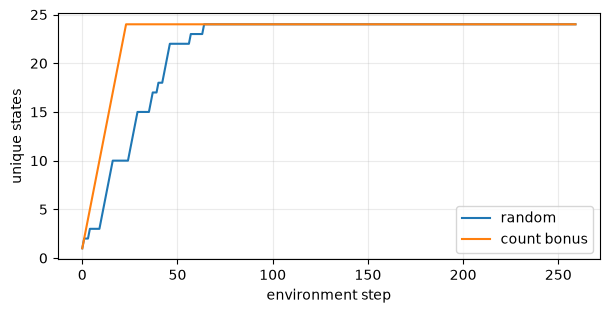

final coverage: 24 24 / 24 steps-to-20: 45 20


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(18)

def explore(use_bonus, steps=260):
    position, counts, coverage = 0, np.zeros(24), []
    for _ in range(steps):
        candidates = np.array([max(0, position - 1), min(23, position + 1)])
        if use_bonus:
            scores = 1 / np.sqrt(counts[candidates] + 1)
            action = rng.choice(np.flatnonzero(scores == scores.max()))
        else:
            action = rng.integers(2)
        position = candidates[action]; counts[position] += 1
        coverage.append(np.count_nonzero(counts))
    return coverage

random_curve, bonus_curve = explore(False), explore(True)
plt.figure(figsize=(7, 3.2)); plt.plot(random_curve, label="random"); plt.plot(bonus_curve, label="count bonus")
plt.xlabel("environment step"); plt.ylabel("unique states"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
random_to_20 = np.flatnonzero(np.asarray(random_curve) >= 20)[0] + 1
bonus_to_20 = np.flatnonzero(np.asarray(bonus_curve) >= 20)[0] + 1
print("final coverage:", random_curve[-1], bonus_curve[-1], "/ 24",
      "steps-to-20:", random_to_20, bonus_to_20)


### 曲线怎么读

count bonus 通常更快扩大覆盖，但覆盖率不是最终任务回报。正式实验应同时画 external return、intrinsic return、unique states，并在评估时关闭 bonus。

### 调参过程：一次只改变一个因素

- 先分别记录外在和内在奖励，绝不只看两者之和。
- 调 bonus scale，使早期能影响行为、后期又不淹没任务奖励。
- RND 再调 observation/error normalization 与 predictor 更新频率。

### 失败案例复盘

- 评估时仍加入 intrinsic reward，报告的任务成绩虚高。
- RND target 网络被 optimizer 更新，奖励定义不断漂移。
- 随机电视等不可预测噪声持续产生高 bonus，agent 原地沉迷。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 分别记录 external 与 intrinsic return。
- 随机电视问题会让预测误差方法沉迷于不可预测噪声。
- 评估策略时通常关闭 exploration bonus/noise。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

让轨迹只在 A/B 循环，再首次访问 C；比较当时的 bonus，并说明它为何鼓励离开熟悉区域。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

A/B 循环后其 count 增大，bonus 下降；首次 C 仍获得 $\beta$。这促使 agent 离开熟悉区域。但若 C 是不可控噪声状态，持续奖励可能有害，因此探索信号必须与可学习、可控制的新奇性结合。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- epsilon-greedy 随机，但不记得哪里已经探索过。
- count bonus 用访问频率表示新奇。
- RND 用预测误差近似高维状态新奇度。
- 内在奖励必须归一化，并警惕随机电视问题。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么 RND target network 不能一起训练？为什么评估时不应把 intrinsic reward 当任务成绩？

<details>
<summary>展开答案</summary>

若 target 也追着 predictor 变化，误差不再稳定表示新奇。intrinsic reward 是训练辅助信号，不是环境真实任务目标。
</details>


## 17. 与前后章节连接

第 19 章也学习一个奖励模型，但其信号来自人类偏好而不是新奇度；两者都存在代理目标被利用的问题。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

pseudo-count 将密度模型推广到大状态空间；episodic memory、ICM 和 disagreement ensembles 是其他常见路线。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-18) · [← 学习索引](../README.md)
